# Comparación de modelos — IC por bootstrap

Notebook **reutilizable** para comparar modelos por sus métricas de validación
con intervalos de confianza (bootstrap *cluster* a nivel línea).

1. **Errorbar**: punto ± IC95% por métrica — la vista *fiel* al IC del bootstrap.
2. **Boxplot** con bigotes en los percentiles 2.5/97.5 (= el IC95%) + cuartiles.

In [1]:
import os
import sys
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Detectar la raíz del repo (donde vive src/) y pararse ahí: así los paths
# relativos de los configs (data/..., configs/...) resuelven como en train.py.
ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.training.save_model import (
    load_cached_results,
    results_cache_key,
    save_cached_results,
)
from src.training.run import run_evaluation
from src.utils.config import load_config
from src.utils.seed import set_seed

print("repo root:", ROOT)

repo root: /Users/octavio/Documents/GitHub/maze genomic pred


In [2]:
# === Modelos a comparar =====================================================
# {etiqueta: ruta_al_config}. Mismo target/env/split (GY, optimal, 2017+2018->2019).
CONFIGS = {
    "GBLUP (REML)": "configs/exp_gblup_2017_2018_to_2019.yaml",
    "XGBoost": "configs/exp_xgboost_2017_2018_to_2019.yaml",
}

METRICS = ("pearson_r", "rmse", "r2")   # portada primero
N_BOOT = 2000      # réplicas de bootstrap (más = IC más estable)
ALPHA = 0.05       # IC del (1-alpha); 0.05 -> IC 95% (percentiles 2.5 / 97.5)

# Evita reentrenar modelos si ya hay resultados cacheados
USE_CACHE = True

FIG_DIR = ROOT / "experiments" / "figs"   
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
def evaluate_model(name, config_path, *, n_boot=N_BOOT, alpha=ALPHA, use_cache=USE_CACHE):
    '''Corre run_evaluation (sin wandb) con bootstrap forzado y devuelve:
       - filas tidy [{model, metric, point, lo, hi}]
       - dict {metric: samples} con la distribución bootstrap por métrica.
    Asume el split fijo (un único fold de validación).

    Con use_cache=True NO reentrena si ya hay resultados cacheados para esta
    (config, seed, n_boot, alpha): los levanta de disco. En miss evalúa y guarda.'''
    cfg = load_config(config_path)
    set_seed(int(cfg.get("seed", 575)))
    cfg.setdefault("bootstrap", {})
    cfg["bootstrap"].update(enabled=True, n_boot=n_boot, alpha=alpha)  # IC siempre on

    key = results_cache_key(cfg, n_boot=n_boot, alpha=alpha)
    res = load_cached_results(key) if use_cache else None
    if res is None:
        res = run_evaluation(cfg)              # sin log_fn => no toca wandb
        save_cached_results(key, res)          # cachea para las próximas corridas
    else:
        print(f"  [cache hit] {name} ({key})")

    fold = res["per_fold"][-1]                 # split fijo: el (único) fold de val
    boot = res["bootstrap"][-1] if res["bootstrap"] else {}

    rows, samples = [], {}
    for m in METRICS:
        rows.append({
            "model": name, "metric": m,
            "point": float(fold.get(m, np.nan)),
            "lo": float(fold.get(f"{m}_lo", np.nan)),
            "hi": float(fold.get(f"{m}_hi", np.nan)),
        })
        samples[m] = np.asarray(boot.get(m, []), dtype=float)
    return rows, samples

In [4]:
rows, samples_by_model = [], {}
for name, path in CONFIGS.items():
    r, s = evaluate_model(name, path)
    rows.extend(r)
    samples_by_model[name] = s
    print(f"[ok] {name}")

df = pd.DataFrame(rows)
df

  [cache hit] GBLUP (REML) (90f1d6fe13802d36)
[ok] GBLUP (REML)
  [cache hit] XGBoost (0a10bbcec8936251)
[ok] XGBoost


,model,metric,point,lo,hi
0,GBLUP (REML),pearson_r,0.314528,0.246174,0.377771
1,GBLUP (REML),rmse,1.301634,1.239727,1.363143
2,GBLUP (REML),r2,-0.664404,-0.873739,-0.490156
3,XGBoost,pearson_r,0.216258,0.144391,0.283914
4,XGBoost,rmse,1.349099,1.288925,1.409123
5,XGBoost,r2,-0.788004,-0.988823,-0.623127


## 1) Errorbar — punto ± IC95%

La forma más fiel de mostrar el IC: el punto es la estimación sobre validación y
los bigotes son los percentiles 2.5 / 97.5 del bootstrap. Ideal para comparar
varios modelos de un vistazo.

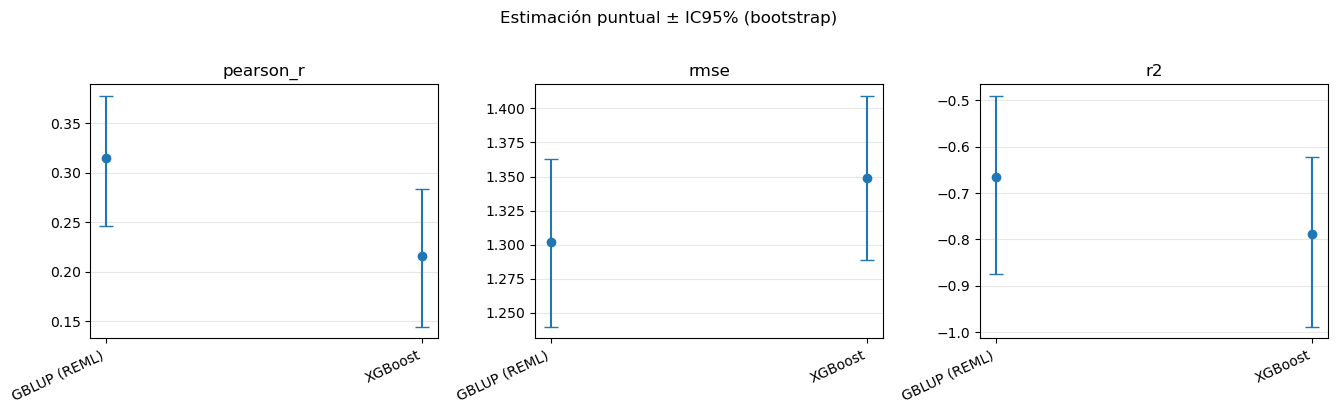

In [5]:
def plot_ci(df, metrics=METRICS, title="Estimación puntual ± IC95% (bootstrap)"):
    '''Un subplot por métrica; cada modelo como punto con bigotes [lo, hi].'''
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.5 * len(metrics), 4))
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, metrics):
        sub = df[df.metric == m].reset_index(drop=True)
        x = np.arange(len(sub))
        point = sub["point"].to_numpy(float)
        lo = sub["lo"].to_numpy(float)
        hi = sub["hi"].to_numpy(float)
        # yerr no-negativo (el punto puede caer fuera del IC en distros sesgadas).
        yerr = np.vstack([np.maximum(point - lo, 0), np.maximum(hi - point, 0)])
        ax.errorbar(x, point, yerr=yerr, fmt="o", capsize=5, lw=1.5, color="tab:blue")
        ax.set_xticks(x)
        ax.set_xticklabels(sub["model"], rotation=25, ha="right")
        ax.set_title(m)
        ax.grid(True, axis="y", alpha=0.3)
    fig.suptitle(title, y=1.02, fontsize=12)
    fig.tight_layout()
    return fig


fig = plot_ci(df)
fig.savefig(FIG_DIR / "ci_errorbars.png", dpi=150, bbox_inches="tight")
plt.show()

## 2) Boxplot de la distribución bootstrap

Un boxplot por default pone los bigotes en 1.5·IQR, que **no** es tu IC. El truco:
`whis=(2.5, 97.5)` deja los bigotes exactamente en el **IC95%**. La caja sigue
mostrando los cuartiles (Q1 / mediana / Q3), así ves forma + IC juntos.
(Pearson del dummy es `nan` → se saltea solo.)

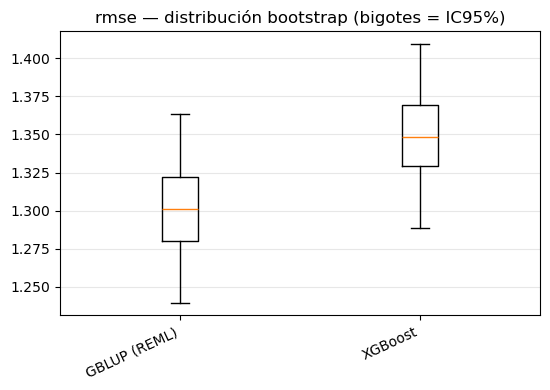

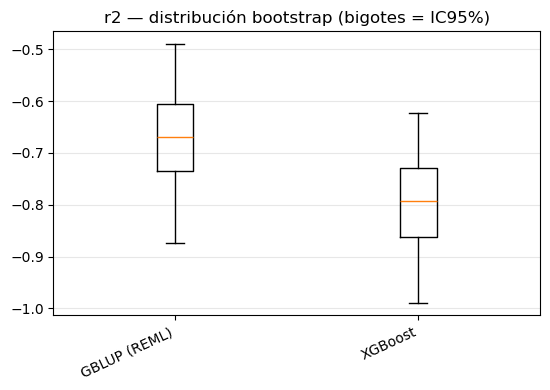

In [6]:
def plot_box(samples_by_model, metric, *, whis=(2.5, 97.5)):
    '''Boxplot de la distribución bootstrap. whis=(2.5, 97.5) => bigotes = IC95%.'''
    models = [k for k, s in samples_by_model.items() if np.isfinite(s[metric]).any()]
    data = [s[metric][np.isfinite(s[metric])]
            for k, s in samples_by_model.items() if np.isfinite(s[metric]).any()]
    if not data:
        print(f"(sin muestras finitas para {metric})")
        return None
    fig, ax = plt.subplots(figsize=(1.8 * len(models) + 2, 4))
    # `tick_labels` se llama `labels` en matplotlib < 3.9: elegir el kwarg vigente.
    import matplotlib as mpl
    label_kw = "tick_labels" if tuple(map(int, mpl.__version__.split(".")[:2])) >= (3, 9) else "labels"
    ax.boxplot(data, whis=whis, showfliers=False, **{label_kw: models})
    ax.set_title(f"{metric} — distribución bootstrap (bigotes = IC95%)")
    ax.grid(True, axis="y", alpha=0.3)
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
    fig.tight_layout()
    return fig


for m in ("rmse", "r2"):
    fig = plot_box(samples_by_model, m)
    if fig is not None:
        fig.savefig(FIG_DIR / f"box_{m}.png", dpi=150, bbox_inches="tight")
        plt.show()

## Notas

- **Un solo fold**: con el split fijo (train 2017-18 / val 2019) hay un único fold
  de validación; el notebook toma ese. El test 2020 queda intocable.
- **Reproducible**: el bootstrap usa la seed del config; misma config → mismo IC.
- **Caché**: con `USE_CACHE = True` cada modelo se evalúa una sola vez por
  (config, seed, `N_BOOT`, `ALPHA`); las corridas siguientes levantan el resultado
  de `outputs/eval_cache` sin reentrenar. Cambiar un hiperparámetro del config
  invalida su entrada sola; poné `USE_CACHE = False` para forzar recómputo.
- **Modelos entrenados**: para reusar un modelo/encoder sin reentrenar, `scripts/train.py` lo guarda como wandb
  Artifact + copia local; se carga con `load_model_artifact(...)` pasando los
  `train_years` del fold para que el chequeo anti-leakage corte cualquier fuga.
- **Figuras**: se guardan en `FIG_DIR` (`experiments/figs`, gitignored)